# 01 - EDA & Preprocessing
Eksplorasi data dan pembuatan cache gambar (resize ke 224x224, grayscale JPEG).

In [1]:
   import shutil; shutil.rmtree("/kaggle/working/document-image-classification-kaggle", ignore_errors=True)

In [2]:
import os, sys, subprocess
REPO_URL = "https://github.com/azizahadilaa/document-image-classification-kaggle.git"
REPO_DIR = "/kaggle/working/document-image-classification-kaggle"
if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
sys.path.append(REPO_DIR)

import pandas as pd, numpy as np, torch
from scripts.utils import set_seed, find_data_dir
set_seed(42)
DATA_DIR = find_data_dir()
CACHE_DIR = "/kaggle/temp/cache"
IMG_SIZE = 224
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(DATA_DIR, train_df.shape, test_df.shape)

Cloning into '/kaggle/working/document-image-classification-kaggle'...


/kaggle/input/competitions/document-image-classification-sd234504 (32003, 4) (7994, 2)


## Distribusi kelas

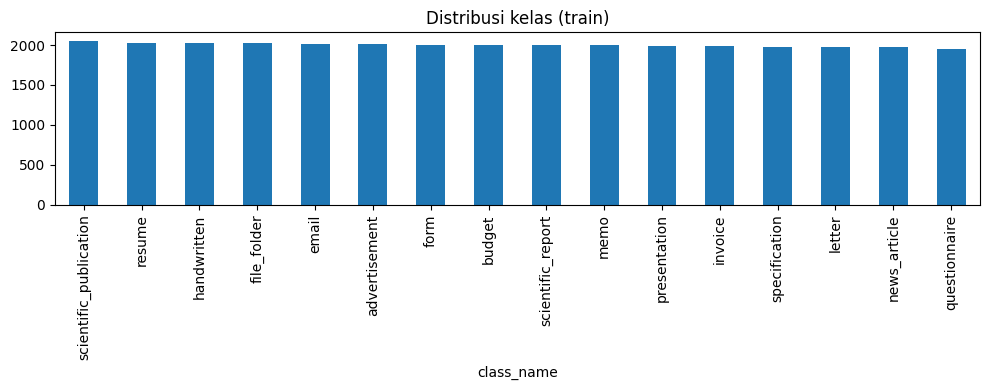

class_name
scientific_publication    2056
resume                    2029
handwritten               2026
file_folder               2022
email                     2013
advertisement             2012
form                      2005
budget                    2004
scientific_report         1999
memo                      1994
presentation              1992
invoice                   1982
specification             1978
letter                    1972
news_article              1971
questionnaire             1948
Name: count, dtype: int64


In [3]:
import matplotlib.pyplot as plt
counts = train_df["class_name"].value_counts()
plt.figure(figsize=(10, 4)); counts.plot(kind="bar"); plt.title("Distribusi kelas (train)")
plt.tight_layout(); os.makedirs(f"{REPO_DIR}/reports/figures", exist_ok=True)
plt.savefig(f"{REPO_DIR}/reports/figures/class_distribution.png", dpi=150); plt.show()
print(counts)

## Contoh gambar tiap kelas

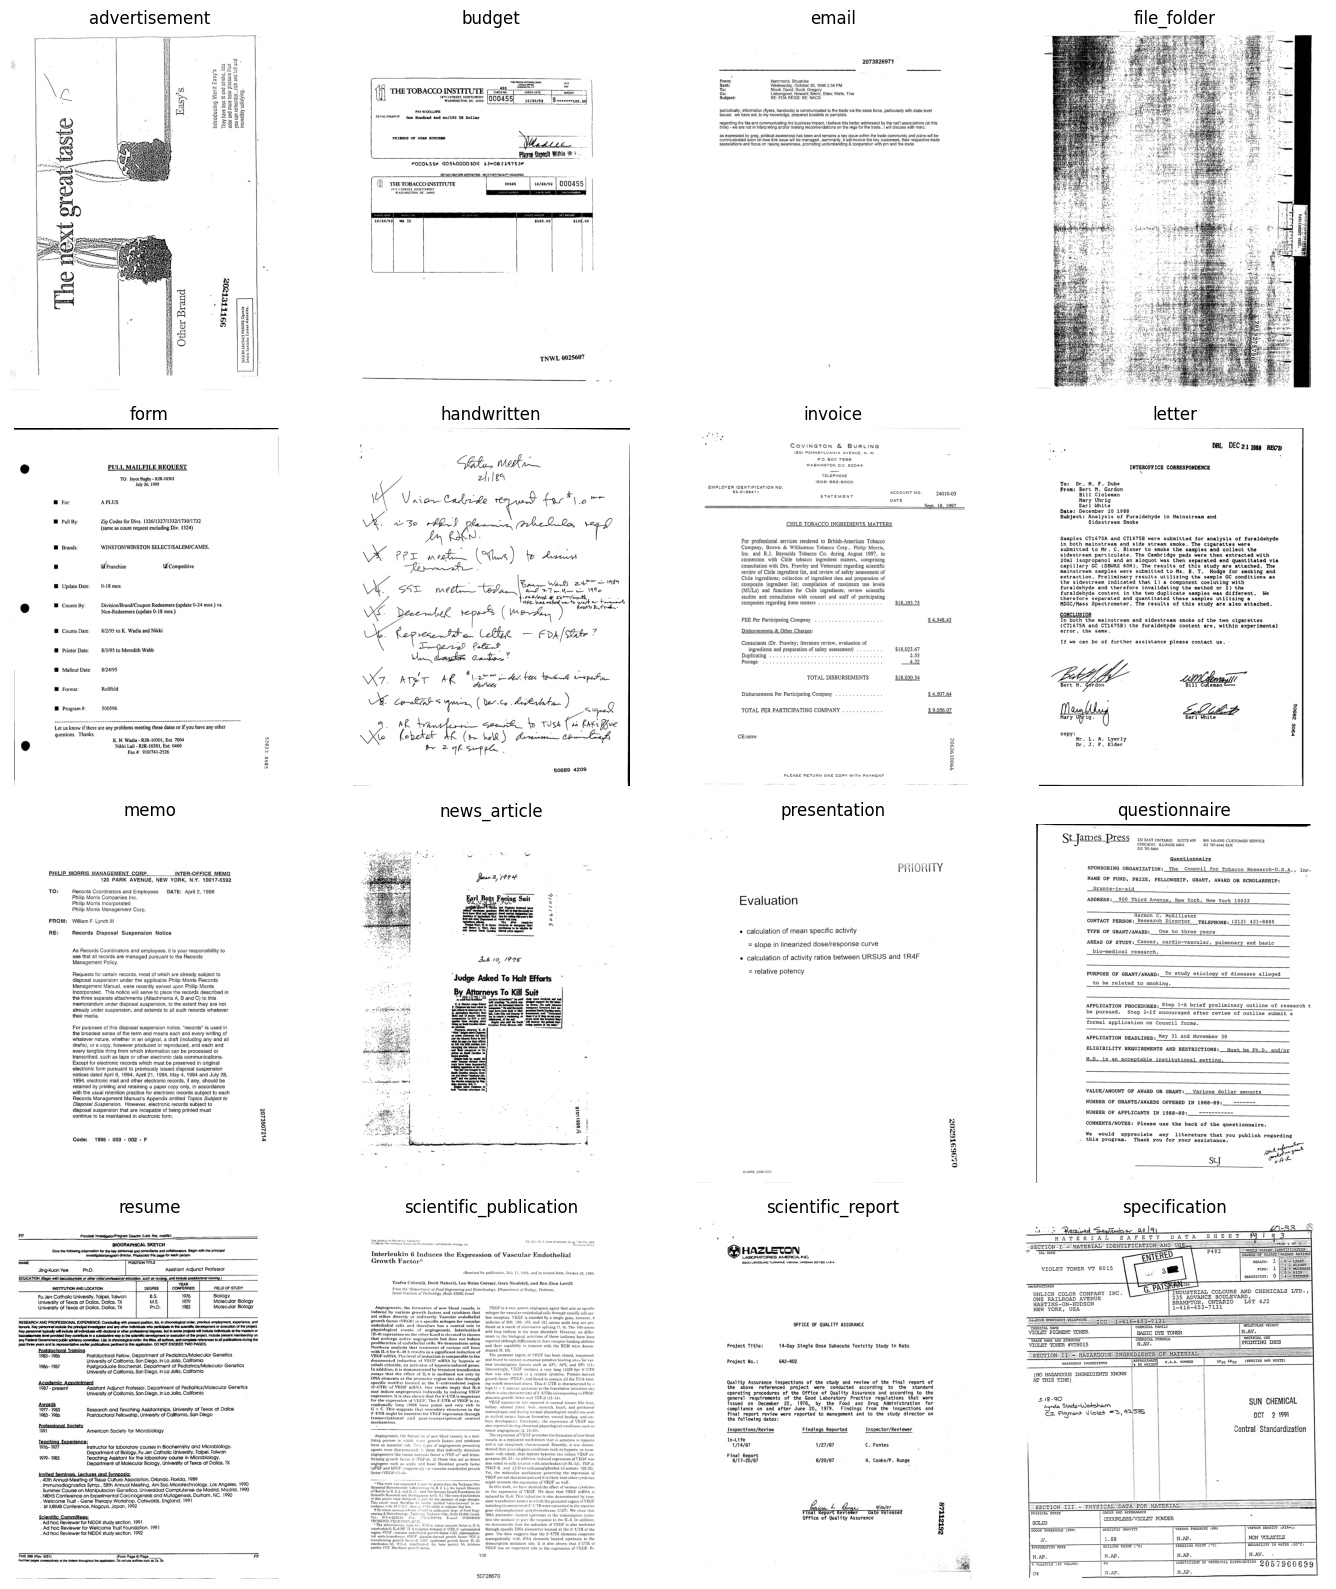

In [4]:
from PIL import Image
from scripts.utils import resolve_path
classes = train_df.sort_values("label")["class_name"].unique()
fig, axes = plt.subplots(4, 4, figsize=(14, 16))
for ax, c in zip(axes.ravel(), classes):
    row = train_df[train_df.class_name == c].iloc[0]
    ax.imshow(Image.open(resolve_path(DATA_DIR, row.filename)).convert("L"), cmap="gray")
    ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{REPO_DIR}/reports/figures/sample_images.png", dpi=120); plt.show()

In [7]:
smp = train_df.sample(500, random_state=0)
print("train ada:", smp["filename"].apply(lambda f: os.path.exists(resolve_path(DATA_DIR, f))).mean())
smp = test_df.sample(500, random_state=0)
print("test ada:", smp["filename"].apply(lambda f: os.path.exists(resolve_path(DATA_DIR, f))).mean())

train ada: 1.0
test ada: 1.0


In [8]:
import os
from scripts.utils import resolve_path

for name, df in [("train", train_df), ("test", test_df)]:
    smp = df.sample(500, random_state=0)
    ok = smp["filename"].apply(lambda f: os.path.exists(resolve_path(DATA_DIR, f)))
    print(name, "ada:", ok.mean())

train ada: 1.0
test ada: 1.0


## Cek ukuran gambar asli (sampel)

In [9]:
sizes = [Image.open(resolve_path(DATA_DIR, f)).size for f in train_df.filename.sample(200, random_state=0)]
print(pd.DataFrame(sizes, columns=["w", "h"]).describe())

                w       h
count  200.000000   200.0
mean   769.475000  1000.0
std     24.151727     0.0
min    713.000000  1000.0
25%    754.000000  1000.0
50%    762.000000  1000.0
75%    777.000000  1000.0
max    872.000000  1000.0


## Cache gambar (sekali jalan, ~10-20 menit)

In [10]:
from scripts.preprocess import cache_images
cache_images(train_df, DATA_DIR, CACHE_DIR, IMG_SIZE)
cache_images(test_df, DATA_DIR, CACHE_DIR, IMG_SIZE)
print(len(os.listdir(CACHE_DIR)), "gambar ter-cache")

 27%|██▋       | 8772/32003 [00:21<00:56, 408.05it/s]/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
100%|██████████| 32003/32003 [01:21<00:00, 394.83it/s]


Selesai: 32002 berhasil, 1 gagal


100%|██████████| 7994/7994 [00:20<00:00, 396.52it/s]


Selesai: 7994 berhasil, 0 gagal
39997 gambar ter-cache
